# Repurposing Lab2 transformer for learning gaussian process

In [2]:
#%pip install -q jax jaxlib matplotlib
#%pip install optax
#%pip install awkward


import sys
from pathlib import Path

import awkward as ak
import pandas as pd

pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import optax
import time
from functools import partial

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT))
from vtx import samples
from vtx.analysis import (load_dev, select_taus, correct_vertex, wilson, efficiency, chosen_z,
                          sumpt2_choice, cone_tracks, tjva_v1, tjva_v2, tjva_andsumpt2,rescue_unassigned)


In [3]:
# [Claude-generated] Make the shared helpers in ML_f26/tools/ importable.
# Jupyter runs this notebook with lab2/ as the working directory, and Python only
# searches that directory (plus installed packages) for modules. tools/ lives one
# level up, so `from tools.plotting import ...` fails until its parent is on sys.path.
import sys
from pathlib import Path

repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "plotting.py").exists())
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from tools.plotting import set_style; set_style()

import os
#os.makedirs("figures", exist_ok=True)  # [Claude-generated] folder for saved figures

## What we change from Lab2 to vertex finder transformer:
1) Tokens should be one candidate vertex feature vector
2) Mask - assign to a real vertex vs padding, because each event has a different vertex count
3) Output head returns one score per vertex, softmaxed to (0,1) instead of (mu, sigma)
4) Loss: softmax over event's vertices, cross entropy against label

# Tokens

In [4]:
GLOBAL = ["log_ntrk", "log_maxpt", "log_sumpt2", "log_sumpt2_rel", "maxpt_rel", "log_dz_nearest"]
TAU    = GLOBAL+["f_v1", "f_v2", "log_cone_pt", "log_dz_sig_leadcone", "dR_lead", "log_jet_pt", "cone_frac", "n_cone"]

def make_tokens_mask(data,taus=None):
    """Makes the tokens for the transformer.
    Inputs:
    Features: nTrks, maxpT (hardest track pt associated with vertex), sumpt2, nearestz (z dist to nearest neighbor),
    Returns: One feature vector per vertex in event, padded with empty vectors up to 250"""
    if taus is None:
        taus = select_taus(data)

    ev = taus.event.values
    sumpt2s  = data.rv_sumpt2[ev] # list of sumpt2 per vertex
    vtx_zs   = data.rv_z[ev]
    n_trks_per_vtx = data.rv_ndf[ev]

    # find maxpT of track associated with vertex
    max_trk_pt_per_vtx = max_trk_pt_per_vertex(data)[ev]

    # find distance to nearest z
    z_dists_matrix = np.abs(vtx_zs[:,:,None] - vtx_zs[:,None,:])
    idx = ak.local_index(vtx_zs, axis=1)
    notselfmask = idx[:, :, None] != idx[:, None, :] #true everywhere except diag of matrix for each event
    dz_other = ak.mask(z_dists_matrix,notselfmask)
    dz_nearest = ak.min(dz_other,axis=1) # per event, a list of dz to neighbor per vertex
    dz_nearest = ak.fill_none(dz_nearest, 300.0) #protect against events with only one vertex, 300 means no neighbor in detector

    # compare sumpt2 and hardest pt of vertex to max values for each event
    relsumpt2 = sumpt2s / ak.max(sumpt2s,axis=-1)
    relmaxpt  = max_trk_pt_per_vtx / ak.max(max_trk_pt_per_vtx,axis=-1)

    #CONE FEATURES (tau-specific features, to be added in ablated training of transformer)
    cone = cone_tracks(data, taus)
    f_v1, cone_pt_v1 = cone_features(cone,cone['vtx'],data,taus) #tjva_v1 score
    f_v2, cone_pt_v2 = cone_features(cone,rescue_unassigned(cone,data,taus),data,taus) # tjva_v2 score, using vertex rescuer

    # for each event, now have (ntrks,maxpt,sumpt2,dz to neighbor) per vertex. make a feature vector per vertex
    # since these features span orders of mag, feed in logs.

    features_global = [np.log(1+ n_trks_per_vtx),np.log(max_trk_pt_per_vtx),
                np.log(sumpt2s), np.log(relsumpt2),relmaxpt, np.log(dz_nearest)]
    features_tau = features_global + [f_v1,f_v2,np.log1p(cone_pt_v2)] + extra_tau_features(data,taus,cone)
    # swap feature axes so that I have structure [[features of v0, ev0, features v1, ev0, ...],[v0,ev1,...]]
    vertex_features_tau    =  ak.concatenate([f[:, :, None] for f in features_tau], axis=-1)
    padded_features_tau   , valid = pad(vertex_features_tau)

    return padded_features_tau, valid
    

def max_trk_pt_per_vertex(data):
    """Claude written fxn
    Per event, per candidate vertex: pT of its hardest track. Same jagged shape as data.rv_index."""
    K = int(ak.max(data.rv_index)) + 1                     # one slot per possible vertex index
    ev  = np.repeat(np.arange(len(data)), ak.to_numpy(ak.num(data.trk_pt)))
    vtx = ak.to_numpy(ak.flatten(data.trk_delphes_vtx))
    pt  = ak.to_numpy(ak.flatten(data.trk_pt))
    ok = vtx >= 0
    table = np.zeros(len(data) * K)
    np.maximum.at(table, ev[ok] * K + vtx[ok], pt[ok])    # (event, vertex) -> one integer key
    ev_v = np.repeat(np.arange(len(data)), ak.to_numpy(ak.num(data.rv_index)))
    flat = table[ev_v * K + ak.to_numpy(ak.flatten(data.rv_index))]
    return ak.unflatten(flat, ak.num(data.rv_index)) 

def pad(feat, n_max=140): # n_max chosen from max number of candidates = 139 at mu=200
    """jagged (n_taus, var_vertices, n_feat) -> padded numpy (n_taus, n_max, n_feat) and valid (n_taus, n_max)"""
    n_vtx = ak.to_numpy(ak.num(feat, axis=1))
    # add an extra 0 for each event's list of feature vectors up to n_max
    X = ak.to_numpy(ak.fill_none(ak.pad_none(feat, n_max, axis=1, clip=True), 0.0))
    n_vtx, X = np.ma.filled(n_vtx, 0), np.ma.filled(X, 0.0) #features containing None
    valid = np.arange(n_max)[None, :] < n_vtx[:, None]        # True for real vertices
    return X.astype(np.float32), valid


# ---------------- Claude-added below (your code above is unchanged) ----------------
def lead_track_per_vertex(data):
    """Claude written fxn
    Per event, per candidate vertex: eta and phi of its hardest track (same jagged shape as data.rv_index).
    Same (event, vertex) -> integer key trick as max_trk_pt_per_vertex."""
    K = int(ak.max(data.rv_index)) + 1
    ev  = np.repeat(np.arange(len(data)), ak.to_numpy(ak.num(data.trk_pt)))
    vtx = ak.to_numpy(ak.flatten(data.trk_delphes_vtx))
    ok = vtx >= 0
    key = (ev * K + vtx)[ok]
    pt, eta, phi = (ak.to_numpy(ak.flatten(x))[ok] for x in (data.trk_pt, data.trk_eta, data.trk_phi))
    order = np.lexsort((pt, key))                            # sort by key, then pT: hardest track is last in each key
    last = np.r_[key[order][1:] != key[order][:-1], True]    # last entry of each key group
    eta_table, phi_table = np.zeros(len(data) * K), np.zeros(len(data) * K)
    eta_table[key[order][last]] = eta[order][last]
    phi_table[key[order][last]] = phi[order][last]
    ev_v = np.repeat(np.arange(len(data)), ak.to_numpy(ak.num(data.rv_index)))
    lookup = ev_v * K + ak.to_numpy(ak.flatten(data.rv_index))
    n = ak.num(data.rv_index)
    return ak.unflatten(eta_table[lookup], n), ak.unflatten(phi_table[lookup], n)


def extra_tau_features(data, taus, cone):
    """Claude written fxn
    The remaining tau-local features, each jagged (n_taus, var_vertices), in the order of TAU after "log_cone_pt":
      dz_sig_leadcone : |z_vertex - z0 of the hardest cone track| / combined error (clipped at 50; 50 if empty cone)
      dR_lead         : dR(jet axis, hardest track of this vertex)
      log_jet_pt      : log(matched jet pT), same value for every vertex of the tau
      cone_frac       : (sum pT of cone tracks) / jet pT, same for every vertex
      n_cone          : number of cone tracks, same for every vertex"""
    ev = taus.event.values
    rv_z, rv_err_z = data.rv_z[ev], data.rv_err_z[ev]
    jet_pt, jet_eta, jet_phi = taus.jet_pt.values, taus.jet_eta.values, taus.jet_phi.values

    # hardest cone track per tau: its z0 and error (None for an empty cone)
    lead = ak.argmax(cone["pt"], axis=1, keepdims=True)
    # empty cone: no hardest track -> put it far away so dz_sig hits the 50 clip (fill before broadcasting!)
    z0_lead  = ak.fill_none(ak.firsts(cone["dz"][lead]), 1e6)
    err_lead = ak.fill_none(ak.firsts(cone["err_dz"][lead]), 1.0)
    dz_sig = np.abs(rv_z - z0_lead) / np.sqrt(rv_err_z**2 + err_lead**2)
    dz_sig_leadcone = np.minimum(dz_sig, 50.0)

    # dR between the jet axis and each vertex's hardest track
    lead_eta, lead_phi = lead_track_per_vertex(data)
    dphi = (lead_phi[ev] - jet_phi + np.pi) % (2*np.pi) - np.pi
    dR_lead = np.sqrt((lead_eta[ev] - jet_eta)**2 + dphi**2)

    # per-tau numbers, copied to every vertex of that tau (rv_z * 0 gives the right jagged shape)
    zeros = rv_z * 0
    log_jet_pt = zeros + np.log(jet_pt)
    cone_frac  = zeros + ak.to_numpy(ak.sum(cone["pt"], axis=1)) / jet_pt
    n_cone     = zeros + ak.to_numpy(ak.num(cone["pt"], axis=1))
    return [np.log1p(dz_sig_leadcone), dR_lead, log_jet_pt, cone_frac, n_cone]


def cone_features(cone, cone_vtx, data, taus):
    """Per tau, per candidate vertex (same order as data.rv_index[ev]): f(v) and the cone pT assigned to the vertex.
    Uses the same (row, vertex) -> integer key trick as max_trk_pt_per_vertex, which also works for empty cones
    (the old version's ak.sum over the cone axis returned an empty list instead of zeros when the cone was empty)."""
    ev = taus.event.values
    rv_index = data.rv_index[ev]
    K = int(ak.max(data.rv_index)) + 1
    tau_of_trk = np.repeat(np.arange(len(taus)), ak.to_numpy(ak.num(cone["pt"])))
    vtx = ak.to_numpy(ak.flatten(cone_vtx))
    pt = ak.to_numpy(ak.flatten(cone["pt"]))
    ok = vtx >= 0
    table = np.zeros(len(taus) * K)
    np.add.at(table, tau_of_trk[ok] * K + vtx[ok], pt[ok])          # cone pT summed per (tau, vertex)
    tau_of_vtx = np.repeat(np.arange(len(taus)), ak.to_numpy(ak.num(rv_index)))
    pt_to_vtx = ak.unflatten(table[tau_of_vtx * K + ak.to_numpy(ak.flatten(rv_index))], ak.num(rv_index))
    tot = ak.to_numpy(ak.sum(cone["pt"], axis=1))
    f = pt_to_vtx / np.where(tot > 0, tot, 1)                         # f(v) for every candidate
    return f, pt_to_vtx


---
## 1. Attention

In [5]:
def init_attention(key, width,n_heads):
    """Initiates the weights for the attention network.
    params: 
    Key: int, jax  key for randomization
    width: int, embedding dimension
    n_heads: int, number of attention heads
    returns: four matrices to be learned"""

    k1, k2, k3, k4 = jax.random.split(key,4)
    queries = jax.random.normal(k1,shape=(width,width)) / jnp.sqrt(width)
    keys    = jax.random.normal(k2,shape=(width,width)) / jnp.sqrt(width)
    values  = jax.random.normal(k3,shape=(width,width)) / jnp.sqrt(width)
    # output projection mixes info from across heads
    output_projection = jax.random.normal(k4,shape=(width,width)) / jnp.sqrt(width)
    return (queries, keys, values, output_projection)
    

def attention(params, tokens, mask, n_heads):
    """Runs the attention mechanism forward"""
    n_tokens = len(tokens[:,0])
    width = len(tokens[0,:])
    d_k = width // n_heads # length of each head
    
    # pass the learned weights as parameters
    query_matrix, key_matrix, value_matrix, output_projection = params

    # query vector for each token is the token's embedding times the query weight matrix
    Q = jnp.matmul(tokens,query_matrix) # has shape (n_tokens, width)
    K = jnp.matmul(tokens,key_matrix) # has shape (n_tokens, width)
    V = jnp.matmul(tokens,value_matrix) # shape (n_tokens, width)

    # split into multiple heads
    outputs = []
    for h in range(n_heads):
        i_start = h*d_k
        i_stop = i_start + d_k
        # split matrices into block for just this head
        Q_h = Q[:,i_start:i_stop]
        K_h = K[:,i_start:i_stop]
        V_h = V[:,i_start:i_stop]
        scores_h = Q_h @ K_h.T / jnp.sqrt(d_k)
        # apply mask so tokens only read context points, not target points
        # jnp.where replaces all instances of False in mask with -inf
        scores_h = jnp.where(mask,scores_h,-jnp.inf)
        output_h = jax.nn.softmax(scores_h, axis=-1) @ V_h
        outputs.append(output_h)
    output = jnp.concatenate(outputs,axis=-1)
    output_mixedheads = output @ output_projection

    return output_mixedheads

def layernorm(tokens,gamma,beta,eps = 1e-5):
    """ compute layer norm on each token's embedding vector
    input: tokens: list of embedded tokens
    eps: used to avoid dividing by 0
    gamma, beta are learned params, need to be trained"""
    mean = jnp.mean(tokens,axis=-1,keepdims=True)
    var = jnp.var(tokens,axis=-1,keepdims=True)
    tokens = (tokens-mean)/jnp.sqrt(var+eps) # should subtract mean from each token's vector
    tokens = gamma*tokens + beta
    return tokens

Check this by running n_heads = 1 and compare to full attention with no splitting

---
## 2. The transformer

Embed the tokens (a small MLP is fine), stack transformer blocks, and read out a mean and a log-variance at each target.
We will assume a Gaussian negative log-likelihood during training. Some reasonable numbers are width 64, 4 heads, 4 layers.

Each step: get a batch of functions, with a random number of context points between 3 and 30, and 30'ish targets as well. 
Feel free to use jax libraries for the optimiser and weight updates (no need to use your solution from the previous tutorial!). 
The number of context points changes the shapes, so `jax.jit` recompiles once per value. That's fine, otherwise you'd need to add some padding

Build the embedding MLP: this model should take the 3 input values for each token (x,y, isContext) (isContext = 1 if context point and = 0 if target point)
and return a vector len 64.

In [6]:
# Build the embedding MLP
# This model should take the 3 values of tokens (x)
def init_mlp(key,layer_sizes):
    n_layers = len(layer_sizes)
    keys = jax.random.split(key,2*(n_layers - 1)) # only need weights and biases for hidden and final layer
    biases = []
    weights = []
    for i, size in enumerate(layer_sizes[1:]): # don't need weights + biases for input layer
        std = jnp.sqrt(2 / layer_sizes[i])
        bias = jax.random.normal(keys[2*i],size) / 10 # try initialize with non-zero biases
        weight = jax.random.normal(keys[2*i+1],(layer_sizes[i],size)) * std
        biases.append(bias)
        weights.append(weight)
    return (weights, biases)

def mlp(params,tokens):
    """Embeds the list of tokens (x,y,isContext) into 64 dim vectors
    inputs:
    params: tuple (weights, biases) with size (n_layers, n_layers)
    tokens: list of tuples for each context+target token

    returns: list of embedding vectors for each token"""
    n_layers = len(params[0]) # length of weights list
    a = tokens
    for i in range(n_layers):
        W = params[0][i]
        b = params[1][i]
        if i < n_layers-1: a = jax.nn.gelu(a @ W + b)
        else: a = a @ W + b

    return a

Create the transformer block: layer norm, attention, residual, MLP, residual

def transformer(n_blocks):

In [7]:
def init_params(key,embedding_dim=64,
                n_heads=4,embedding_size=(len(TAU),64,64),umembedding_size=(64,64,1),
                forward_mlp_size=(64,64*4,64),n_blocks=4,global_only=False):
    k_embed, k_unemb,k_f,k_atts = jax.random.split(key,4)
    k_forward = jax.random.split(k_f,n_blocks)
    k_atts = jax.random.split(k_atts,n_blocks)
    if global_only: embedding_size=(len(GLOBAL),64,64)
    
    embedding_params = init_mlp(k_embed,embedding_size)
    unembedding_params = init_mlp(k_unemb,umembedding_size)
    

    # store one copy of MLP params for each block using dict
    # and one copy of attention params for each block
    attention_params = {}
    forward_mlp_params = {}
    layernorm1_params = {}
    layernorm2_params = {}

    gamma_i = jnp.ones(embedding_dim)
    beta_i = jnp.zeros(embedding_dim)
    layernormfinal_params = (gamma_i, beta_i)
    
    for i in range(n_blocks):
        # keys
        k_thisforward = k_forward[i]
        k_att = k_atts[i]

        forward_mlp_params[f"block_{i}"] = init_mlp(k_thisforward,forward_mlp_size)
        attention_params[f"block_{i}"] = init_attention(k_att,embedding_dim,n_heads)
        layernorm1_params[f"block_{i}"] = (gamma_i, beta_i)
        layernorm2_params[f"block_{i}"] = (gamma_i, beta_i)
        #blocks.append({"ln1:": (gamma_i,beta_i), "ln2": (gamma_i,beta_i)
                       #"attention:": (att_params_i), "mlp"})


    return (embedding_params, attention_params,layernorm1_params,
            forward_mlp_params,layernorm2_params,
            layernormfinal_params,unembedding_params)

def transformer(params,tokens_raw,mask,n_heads,n_blocks=4):
    """Runs transformer forward to combine embedding,layernorm,attention,
    layernorm,MLP,unembedding.
    Output: (predicted y, log of pred var): shape (n_tokens,2)"""
    # call params
    embedding_params, attention_params,layernorm1_params,forward_mlp_params,layernorm2_params,layernormfinal_params,unembedding_params = params
    # embed tokens
    tokens = mlp(embedding_params,tokens_raw) # embedded tokens

    # do layer norm->attention->residual->MLP->residual for each block
    for i in range(n_blocks):
        att_params_i = attention_params[f"block_{i}"]
        forward_params_i = forward_mlp_params[f"block_{i}"]
        gamma1, beta1 = layernorm1_params[f"block_{i}"]
        gamma2, beta2 = layernorm2_params[f"block_{i}"]

        # apply attention and add to residual
        # apply layer norm to tokens before passing to attention
        tokens += attention(att_params_i,layernorm(tokens,gamma1,beta1),mask,n_heads)
        # apply forward pass MLP and add to residual
        tokens += mlp(forward_params_i,layernorm(tokens,gamma2,beta2))

    #apply final layer norm after last block
    gamma_f, beta_f = layernormfinal_params
    tokens = layernorm(tokens,gamma_f,beta_f)

    # use MLP to unembed: send token vectors -> (x,y)
    # shape (n_tokens,2), each output [predicted y, log of pred var)
    output_unembedded = mlp(unembedding_params,tokens) 
    return output_unembedded

def run_transformer(params,tokens, valid):
    """Running the transformer forward
    Inputs params (learned and updated), tokens, valid (if each vertex token is real or padding)
    Output score per vertex, per event
    """
    mask = valid[:, None, :] & np.ones((1, valid.shape[1], 1), bool)   # (n_taus, n_max, n_max): row i, column j = valid[j]

    # for a single fxn's token, run transofmrer with shared params and mask
    # vmap applies to every row of the batch axis
    out = jax.vmap(lambda t, m: transformer(params, t, m, N_HEADS))(tokens, mask)   # (B, n_max, 1)

    scores = out[:, :, 0]
    scores = jnp.where(valid,scores,-1e9)
    return scores

def loss_fn(params,tokens,valid,label_pos):
    """Calculates loss by running the transformer forward
    Inputs params (learned and updated, for running transformer forward pass), 
    tokens (for running forward pass), valid (which tokens are real vertices, for building mask, output of pad()),
    label_pos (truth label positions generated from labels in dataset build)

    Uses cross-entropy loss, sum(y * log(p_k)), where y are truth labels, p_k is softmax of transformer output
    Outputs ave  over all batches"""

    scores = run_transformer(params,tokens,valid)
    logp_softmax = jax.nn.log_softmax(scores,axis=-1)
    # in the sum, only the true vertex has y=1, all others have y=0, so collapse to x_ent = log(p_k)
    # take the logp only where the truth label exists
    xentropy_perev = jnp.take_along_axis(logp_softmax,label_pos[:,None],axis=1)
    xent_ave = -jnp.mean(xentropy_perev)
    return jnp.mean(xent_ave)

In [8]:
@partial(jax.jit, static_argnames="loss_fn")
def train_step(params,loss_fn,opt_state,tokens,valid,label_pos):
    """Apply one step of training.
    Input params (current state of all transformer parameters),
    opt_state (current set of parameters for optimizer, eg Adam's beta),
    xc,yc,xt,yt to be pulled from sample.
    Output: updated params, opt_state, loss (calculated with jax gradients)"""
    loss, grads = jax.value_and_grad(loss_fn)(params,tokens,valid,label_pos)
    updates, opt_state = opt.update(grads,opt_state,params)
    params = optax.apply_updates(params,updates)
    return params, opt_state, loss

In [9]:
def build_dataset(data, taus):
    X, valid = make_tokens_mask(data, taus)
    ev = taus.event.values
    label = ak.to_numpy(correct_vertex(data))[ev]                              # rv_index value, -1 = none
    rvi = ak.to_numpy(ak.fill_none(ak.pad_none(data.rv_index[ev], 140, axis=1, clip=True), -9))
    label_pos = np.argmax(rvi == label[:, None], axis=1)                       # POSITION in the token list
    keep = (label >= 0) & valid.any(axis=1)                                    # drop no-label / zero-vertex taus
    split = samples.split_of(ak.to_numpy(data.event_id)[ev])                   # same split as the baselines
    return dict(tokens=X[keep], valid=valid[keep], label_pos=label_pos[keep], 
                rvi=rvi[keep], split=split[keep],row=np.where(keep)[0])

In [10]:
#  claude generated
# build dataset once and save
from vtx.analysis import COLS
MU_ALL = [0, 30, 50, 100, 140, 200]
TOK_DIR = PROJECT / "samples" / "tokens"
TOK_DIR.mkdir(exist_ok=True)
for mu in MU_ALL:
    f = TOK_DIR / f"mu{mu}.npz"
    if f.exists():
        continue
    data = samples.load(mu, slices=samples.SLICES, columns=COLS)
    np.savez(f, **build_dataset(data, select_taus(data)))
    print(mu, "saved")
    del data


In [11]:
# claude gen'd, generated total training set out of mixed mu
parts = [dict(np.load(TOK_DIR / f"mu{mu}.npz")) for mu in MU_ALL]
D = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}             # one big dataset
D["mu"] = np.concatenate([np.full(len(p["label_pos"]), mu) for p, mu in zip(parts, MU_ALL)])

tr = D["split"] == "train"
real_train = D["tokens"][D["valid"] & tr[:, None]]                           # (n_real_vertices, 14)
mean, std = real_train.mean(0), real_train.std(0) + 1e-6
D["tokens"] = ((D["tokens"] - mean) / std).astype(np.float32)
D["tokens"][~D["valid"]] = 0.0                                                # padding stays exactly 0
print({mu: (tr & (D["mu"] == mu)).sum() for mu in MU_ALL})


{0: np.int64(17211), 30: np.int64(16083), 50: np.int64(15375), 100: np.int64(13841), 140: np.int64(12945), 200: np.int64(11440)}


D is a dictionary, and every entry has one row per tau, in the same order. Row 5000 of D["tokens"] is the same tau as row 5000 of D["valid"], D["label_pos"], D["split"] and D["mu"]:

key	shape	what row i holds
D["tokens"]	(n_taus, 140, 14)	the feature vectors of tau i's candidate vertices, padded to 140
D["valid"]	(n_taus, 140)	True where tau i has a real vertex, False on padding
D["label_pos"]	(n_taus,)	the position (0–139) of the correct vertex in tau i's token list
D["split"]	(n_taus,)	"train", "val" or "test"
D["mu"]	(n_taus,)	the μ value of tau i's file
D["rvi"]	(n_taus, 140)	the rv_index at each position (only needed to map back to your per-tau tables)
D["row"]	(n_taus,)	which row of per_tau[mu] this tau is
Since all entries share the row order, one True/False array of length n_taus can select the same taus from every entry:

In [32]:
tokens = D['tokens'] # feature vectors for teach tau's candidate vertices, padded to 140
valid = D['valid'] # bool mask, 1 if real vertex, 0 pad
label_pos = D['label_pos'] # the pos (0-139) of the correct vertex in each tau's token list
rvi = D['rvi']
split = D['split'] # shape (n_taus,), train, test, or val for each tau
mu_of_tau = D['mu'] #mu value of each tau's source file
rvi = D['rvi'] # rv_index at each position, used to map back to per-tau tables
row = D['row'] # which row of per_tau[mu] this tau is
print(f"total number of taus over all 6 mu values: {len(split)}")


total number of taus over all 6 mu values: 125310


In [29]:

# training
opt = optax.adam(1e-3) #pick adam as optimizer, learning rate from previous lab
key = jax.random.key(19)
key, k_init = jax.random.split(key,2)
N_BATCH = 64
N_HEADS = 4

params = init_params(k_init,embedding_size=(tokens.shape[-1],64,64))
opt_state = opt.init(params)
run_jit = jax.jit(run_transformer)

start = time.time()

losses = []; val_losses = []
times = []
n_trainsteps = 1500

idx_tr = np.where(tr)[0]   # the row numbers /events of all training taus, e.g. [0, 2, 3, 7, ...]
idx_va = rng_va = np.random.default_rng(1).choice(np.where(D["split"] == "val")[0], 512, replace=False)
rng = np.random.default_rng(0)           # a seeded random number generator, so reruns give the same batches

window = 100 # how often to get the val loss
trainsteps = np.arange(n_trainsteps)
trainsteps_val = np.arange(n_trainsteps,jump)
for step in trainsteps:
    #minibatching 
    b = rng.choice(idx_tr, 64, replace=False)  # each step: 64 random training rows (events)

    # run training forward, runs whole transformer and NLL loss calc and gradients, on 64 rows
    params, opt_state, loss = train_step(params,loss_fn,opt_state,tokens[b], valid[b], label_pos[b])
    losses.append(float(loss))
    times.append(time.time()-start)
    if step % window == 0: 
        vl = np.mean([float(loss_fn(params, D["tokens"][c], D["valid"][c], D["label_pos"][c]))
                      for c in np.split(idx_va, 8)])                          # val loss on a fixed 512 taus
        val_losses.append((step, vl))
        print(f"step {step}: train {loss:.3f}, val {vl:.3f}, {time.time() - start:.0f}s")


step 0: train 4.059, val 2.413, 1s
step 100: train 0.107, val 0.356, 15s
step 200: train 0.175, val 0.345, 30s
step 300: train 0.179, val 0.348, 44s
step 400: train 0.114, val 0.339, 59s
step 500: train 0.264, val 0.334, 74s
step 600: train 0.494, val 0.329, 89s
step 700: train 0.225, val 0.347, 103s
step 800: train 0.281, val 0.324, 117s
step 900: train 0.095, val 0.311, 132s
step 1000: train 0.414, val 0.318, 146s
step 1100: train 0.252, val 0.320, 160s
step 1200: train 0.105, val 0.320, 174s
step 1300: train 0.041, val 0.302, 188s
step 1400: train 0.096, val 0.319, 202s


In [31]:
tokens_g = tokens[:,:,:len(GLOBAL)] #feature vectors excluding tau-specific features
params_g = init_params(k_init,embedding_size=(len(GLOBAL),64,64))
opt_state_g = opt.init(params_g)
start = time.time()

losses_g = []; val_losses_g = []

## train on only the global features
for step in trainsteps:
    #minibatching 
    b = rng.choice(idx_tr, 64, replace=False)  # each step: 64 random training rows (events)

    # run training forward, runs whole transformer and NLL loss calc and gradients, on 64 rows
    params_g, opt_state_g, loss = train_step(params_g,loss_fn,opt_state_g,tokens_g[b], valid[b], label_pos[b])
    losses_g.append(float(loss))
    if step % window == 0: 
        vl = np.mean([float(loss_fn(params_g, tokens_g[c], valid[c], label_pos[c]))
                      for c in np.split(idx_va, 8)])                          # val loss on a fixed 512 taus
        val_losses_g.append((step, vl))
        print(f"step {step}: train {loss:.3f}, val {vl:.3f}, {time.time() - start:.0f}s")

step 0: train 4.585, val 2.873, 1s
step 100: train 0.411, val 0.517, 15s
step 200: train 0.384, val 0.502, 30s
step 300: train 0.589, val 0.517, 44s
step 400: train 0.305, val 0.499, 58s
step 500: train 1.055, val 0.503, 73s
step 600: train 0.392, val 0.500, 87s
step 700: train 0.452, val 0.503, 101s
step 800: train 0.770, val 0.510, 115s
step 900: train 0.108, val 0.534, 129s
step 1000: train 0.416, val 0.504, 143s
step 1100: train 0.448, val 0.497, 157s
step 1200: train 0.309, val 0.491, 171s
step 1300: train 0.195, val 0.490, 185s
step 1400: train 0.364, val 0.494, 199s


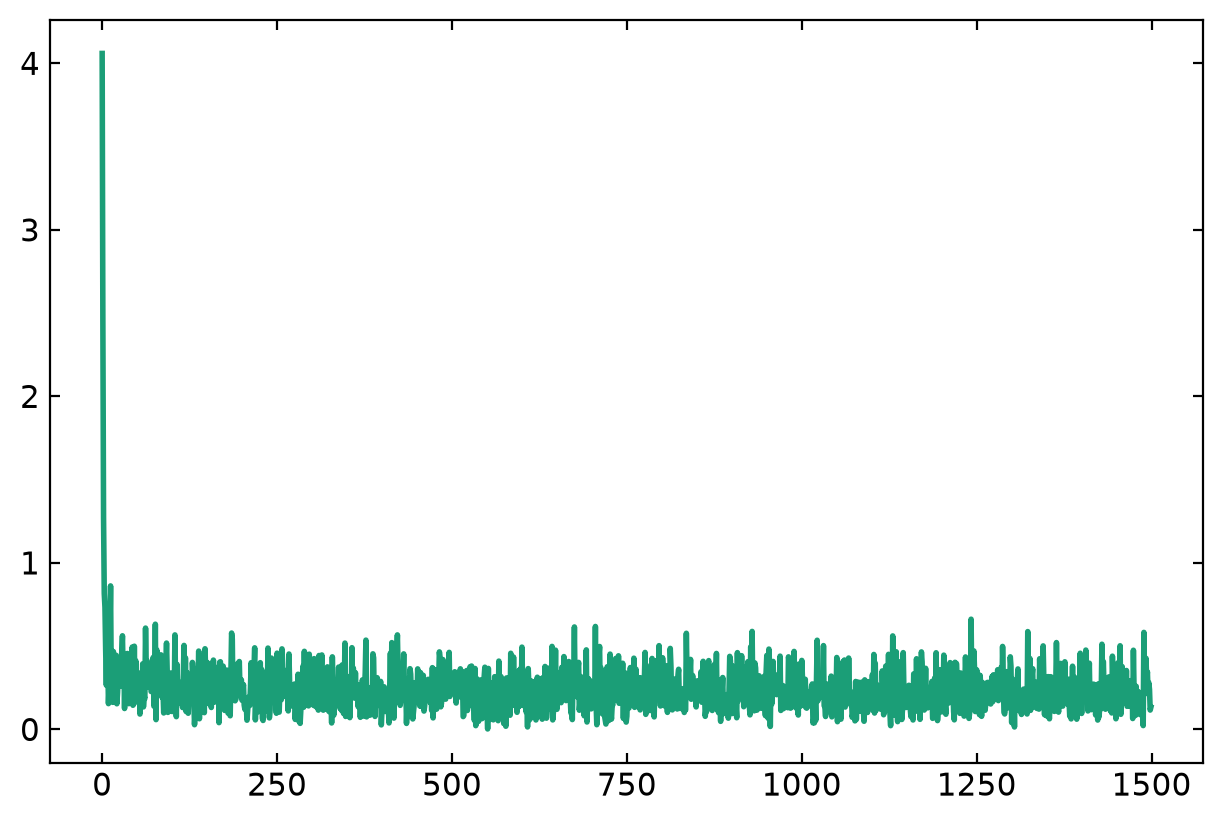

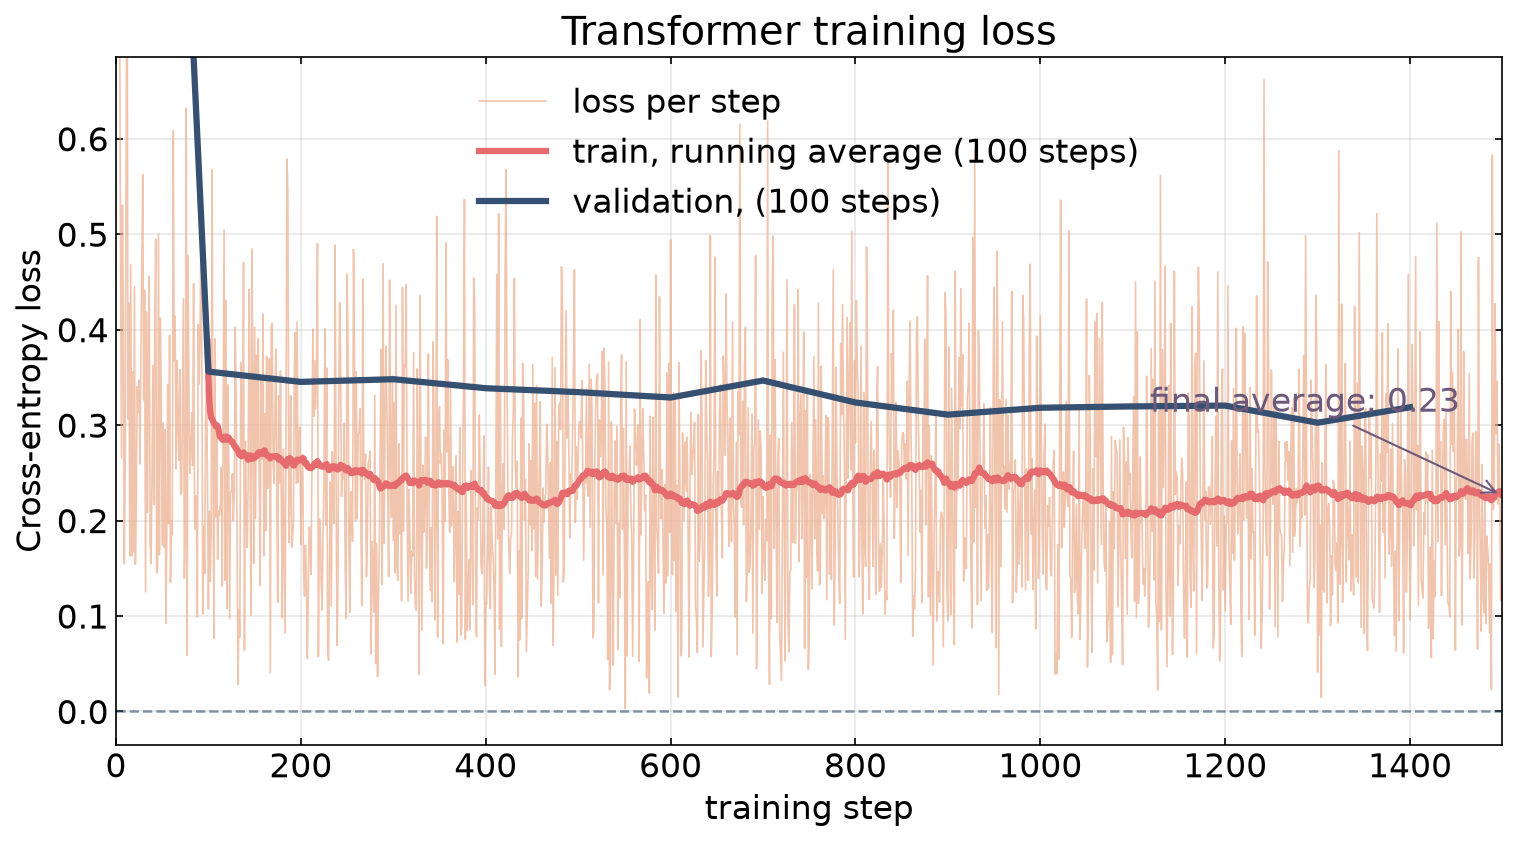

In [34]:
# plot loss
plt.figure(figsize=(6,4),dpi=200)
plt.plot(trainsteps,losses)

# [Claude-generated] Training loss with a running average.
# The raw loss jumps around because every step draws a new n_ctx (3-30) and new
# functions, so a moving average is plotted on top to show the trend underneath.
SUNSET = {"dusk": "#355070", "plum": "#6d597a", "rose": "#b56576",
          "coral": "#e56b6f", "peach": "#eaac8b", "gold": "#f6bd60"}

loss_arr = np.asarray(losses)
running_avg = np.convolve(loss_arr, np.ones(window) / window, mode="valid")
avg_steps = np.asarray(trainsteps)[window - 1:]   # each average covers the `window` steps ending here

with plt.rc_context({"font.size": 16}):
    fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150, layout="constrained")
    ax.plot(trainsteps, loss_arr, color=SUNSET["peach"], lw=0.8, alpha=0.7, label="loss per step")
    ax.plot(avg_steps, running_avg, color=SUNSET["coral"], lw=3, label=f"train, running average ({window} steps)")
    ax.plot([step for step, v in val_losses], [v for s,v in val_losses], color=SUNSET["dusk"], lw=3, label=f"validation, ({window} steps)")
    ax.axhline(0, color=SUNSET["dusk"], lw=1.2, ls="--", alpha=0.6)

    # clip the y-range to the bulk of the raw losses so rare spikes don't squash the curve
    lo, hi = np.percentile(loss_arr, [0.5, 99.5])
    ax.set_ylim(lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))
    ax.set_xlim(0, len(loss_arr))

    ax.annotate(f"final average: {running_avg[-1]:.2f}", xy=(avg_steps[-1], running_avg[-1]),
                xytext=(-20, 40), textcoords="offset points", ha="right", color=SUNSET["plum"],
                arrowprops=dict(arrowstyle="->", color=SUNSET["plum"]))
    ax.set_xlabel("training step")
    ax.set_ylabel("Cross-entropy loss")
    ax.set_title("Transformer training loss")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)
    #fig.savefig("figures/transformer_loss.png")  # [Claude-generated] save figure for the report
    plt.show()

In [51]:
## Evaluate transformer predictions for each mu

EVAL_SPLIT = 'val'
def transformer_choice(params,tokens_i,valid_i,rvi_i):
    # do chunking over 256 taus at a time
    bestvtx_allchunks = []
    for chunk_start in range(0,len(tokens_i),256):
        tokens_ic = tokens_i[chunk_start : chunk_start + 256]
        valid_ic = valid_i[chunk_start : chunk_start + 256]

        # run transformer on this chunk of tokens, for this mu
        scores = run_jit(params,tokens_ic,valid_ic) # (n_taus_thismu,140)
        bestvtx_thischunk = np.argmax(scores,axis=-1) # index (0-139) of best vertex per event
        bestvtx_allchunks.append(bestvtx_thischunk)

    bestvtx = np.concatenate(bestvtx_allchunks)
    tau_num = np.arange(len(bestvtx))
    bestvtx_rvi = rvi_i[tau_num,bestvtx]
    return bestvtx, bestvtx_rvi

# get data from analysis.ipynb (efficiencies for other algorithms, and weights)
per_tau_table = pd.read_pickle(PROJECT / "samples" / "per_tau.pkl")

# unweighted
eff_ts = []
eff_gs = []

print('unweighted efficiencies of transformer on validation taus')
for mu_i in MU_ALL:
    print(f"mu: {mu_i}")
    isthismu = mu_of_tau == mu_i
    isval = split == EVAL_SPLIT
    select = isthismu & isval

    tokens_i = tokens[select]
    valid_i = valid[select]
    label_pos_i = label_pos[select]
    rvi_i = rvi[select] # used for reordering position->rvi index

    table_i = per_tau_table[mu_i]

    bestvtx_t, choice_trans_t = transformer_choice(params,tokens_i,valid_i,rvi_i)
    bestvtx_g, choice_trans_g = transformer_choice(params_g,tokens_g[select],valid_i,rvi_i)

    eff_t = np.mean((bestvtx_t == label_pos_i))
    eff_ts.append(eff_t)
    eff_g = np.mean((bestvtx_g == label_pos_i))
    eff_gs.append(eff_g)
    print(f'eff_t: {eff_t:.2f}, eff_g = {eff_g:.2f}')

    # reorganize best vertex choices to match structure of per_tau_table
    # start by filling empty array with -2, for val or test taus, and for taus with no good vertex
    choice_per_row_t = np.full(len(table_i),-2) #-2 for taus that the transformer did not run on
    choice_per_row_g = np.full(len(table_i),-2) #-2 for taus that the transformer did not run on

    # now fill in the taus with a transformer prediction with the prediction from the forward pass
    # row = D['row'], which row of per_tau[mu] this tau is
    # need to do this linking between the per_tau table which includes every selected tau
    # and the build_dataset D table that drops taus with no good vertex
    choice_per_row_t[row[select]] = choice_trans_t
    choice_per_row_g[row[select]] = choice_trans_g

    trans_t_correct = (choice_per_row_t == table_i.label) & table_i.has_label
    trans_g_correct = (choice_per_row_g == table_i.label) & table_i.has_label

    table_i["transformer_t"] = trans_t_correct
    table_i["transformer_g"] = trans_g_correct


unweighted efficiencies of transformer on validation taus
mu: 0
eff_t: 1.00, eff_g = 1.00
mu: 30
eff_t: 0.95, eff_g = 0.91
mu: 50
eff_t: 0.94, eff_g = 0.89
mu: 100
eff_t: 0.91, eff_g = 0.86
mu: 140
eff_t: 0.92, eff_g = 0.86
mu: 200
eff_t: 0.90, eff_g = 0.85


/var/folders/1f/v2ws8crn4c34nx9fvpdjdb2c0000gn/T/ipykernel_21862/2053159966.py:32: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


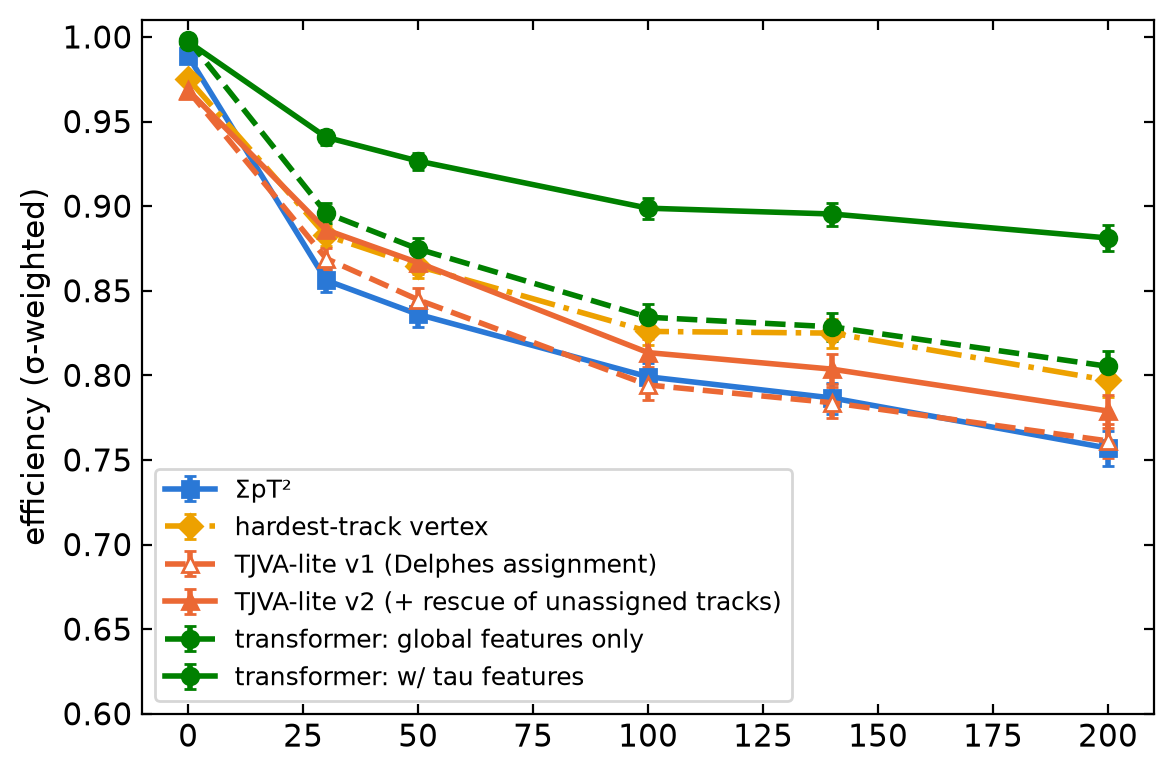

In [57]:
import matplotlib.ticker

# Efficiency plots from the per-tau tables (per_tau[mu]).
# "rel. to ceiling" = Sebastian's / THOR definition: denominator = taus whose event has an HS vertex.
BLUE, ORANGE, YELLOW, GRAY = "#2a78d6", "#eb6834", "#eda100", "#9a9993"
STYLE = {"sumpt2":        dict(color=BLUE,   marker="s", ls="-",  label="ΣpT²"),
         "hardest track": dict(color=YELLOW, marker="D", ls="-.", label="hardest-track vertex"),
         "tjva v1":       dict(color=ORANGE, marker="^", ls="--", mfc="white", label="TJVA-lite v1 (Delphes assignment)"),
         "tjva v2":       dict(color=ORANGE, marker="^", ls="-",  label="TJVA-lite v2 (+ rescue of unassigned tracks)"),
         "transformer_g": dict(color='green', marker="o", ls="--", label="transformer: global features only"),
         "transformer_t": dict(color='green', marker="o", ls="-", label="transformer: w/ tau features")}

def plot_eff(ax, x, tables, method, weighted=True, rel_ceiling=True, **kw):
    """One efficiency curve: x values and one per-tau table per x point."""
    effs, los, his = [], [], []
    for t in tables:
        t = t[t.has_label] if rel_ceiling else t
        e, lo, hi = efficiency(t[method], t.w if weighted else None)
        effs.append(e); los.append(lo); his.append(hi)
    effs = np.array(effs)
    ax.errorbar(x, effs, yerr=[effs - los, np.array(his) - effs], ms=6, capsize=2, **{**STYLE.get(method, {}), **kw})

# 1) efficiency vs mu, sigma-weighted:  relative to the ceiling 
test_tables = [per_tau_table[mu_value][per_tau_table[mu_value].split == EVAL_SPLIT] for mu_value in MU_ALL]

fig, ax = plt.subplots(figsize=(6,4),dpi=200)
for m in STYLE:
    plot_eff(ax, MU_ALL, test_tables, m, rel_ceiling=True)
ax.set_ylabel("efficiency (σ-weighted)")
ax.legend(fontsize=9)                   
ax.set_ylim(0.6, 1.01)  
plt.tight_layout()                

  mu =   0: sumpt2 0.993, tjva v1 0.992, tjva v2 0.992
  mu =  30: sumpt2 0.873, tjva v1 0.891, tjva v2 0.911
  mu =  50: sumpt2 0.845, tjva v1 0.864, tjva v2 0.885
  mu = 100: sumpt2 0.806, tjva v1 0.825, tjva v2 0.849
  mu = 140: sumpt2 0.792, tjva v1 0.805, tjva v2 0.829
  mu = 200: sumpt2 0.772, tjva v1 0.792, tjva v2 0.813

mu: 0
eff_t: 0.9970477724100912, eff_g = 0.9981213097155126
mu: 30
eff_t: 0.9505605058924979, eff_g = 0.9149180799080195
mu: 50
eff_t: 0.9353772167117523, eff_g = 0.8941989780583108
mu: 100
eff_t: 0.9140180662428906, eff_g = 0.8621612579458012
mu: 140
eff_t: 0.9151183970856102, eff_g = 0.8619307832422587
mu: 200
eff_t: 0.9006085192697769, eff_g = 0.847870182555781